In [1]:
# Imports the needed modules, classes and functions from the required packages

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import metpy.plots as mpplots
import pandas as pd

from wxdata import gfs_0p25
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patheffects import withStroke
from datetime import timedelta

In [2]:
# Uses the WxData Client to retrieve our queried GFS 0.25x0.25 data

ds = gfs_0p25(variables=['geopotential height',
                         'absolute vorticity',
                         'u-component of wind',
                         'v-component of wind'],
             levels=[500],
             western_bound=-130,
             eastern_bound=-65,
             southern_bound=20,
             northern_bound=60,
             final_forecast_hour=72)

Writing GRIB messages     |                              | 0/4

ABSV @ 500 mb                  |                              |   0% [0.00/110k]

HGT @ 500 mb                   |                              |   0% [0.00/100k]

UGRD @ 500 mb                  |                              |   0% [0.00/67.8k]

VGRD @ 500 mb                  |                              |   0% [0.00/68.4k]

Writing GRIB messages     |                              | 0/4

... (116 outputs left out)

HGT @ 500 mb                   |                              |   0% [0.00/98.6k]

UGRD @ 500 mb                  |                              |   0% [0.00/66.1k]

VGRD @ 500 mb                  |                              |   0% [0.00/66.5k]

GFS0P25 Download Complete
GFS0P25 Data Processing...
GFS0P25 Data Processing Complete.


In [3]:
# Inspect our data in Jupyter Lab

ds

<xarray.Dataset> Size: 17MB
Dimensions:              (step: 25, latitude: 161, longitude: 261)
Coordinates:
  * step                 (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * latitude             (latitude) float64 1kB 60.0 59.75 59.5 ... 20.25 20.0
  * longitude            (longitude) float64 2kB -130.0 -129.8 ... -65.25 -65.0
    time                 datetime64[ns] 8B ...
    isobaricInhPa        float64 8B ...
    valid_time           datetime64[ns] 8B ...
Data variables:
    geopotential_height  (step, latitude, longitude) float32 4MB dask.array<chunksize=(1, 161, 261), meta=np.ndarray>
    u_wind_component     (step, latitude, longitude) float32 4MB dask.array<chunksize=(1, 161, 261), meta=np.ndarray>
    v_wind_component     (step, latitude, longitude) float32 4MB dask.array<chunksize=(1, 161, 261), meta=np.ndarray>
    absolute_vorticity   (step, latitude, longitude) float32 4MB dask.array<chunksize=(1, 161, 261), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-11-24T12:23 GRIB to CDM+CF via cfgrib-0.9.1...

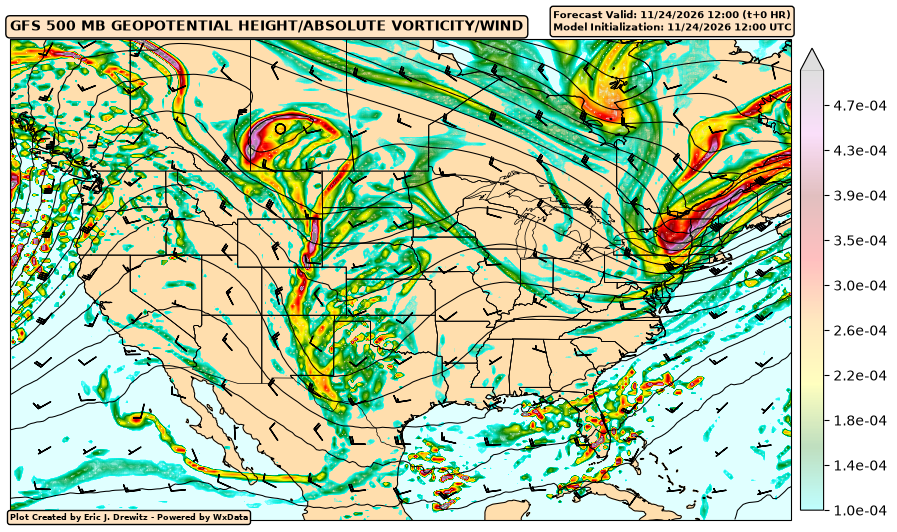

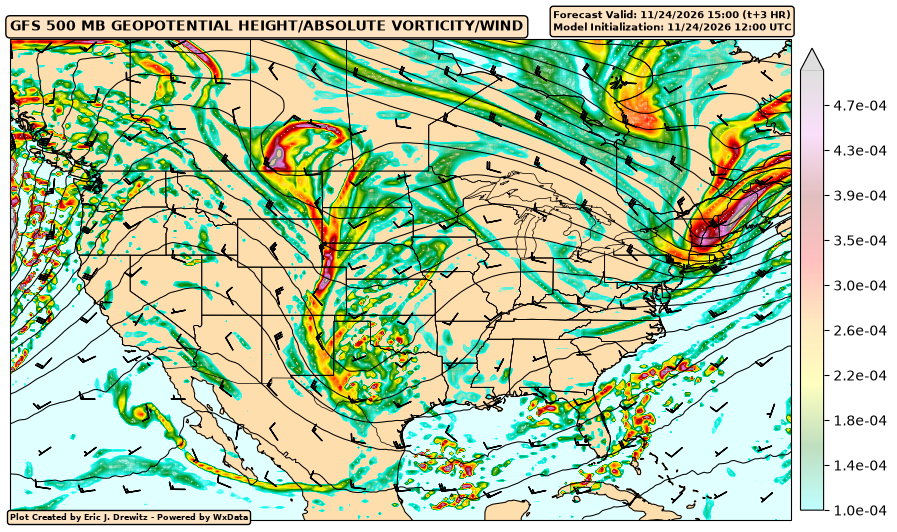

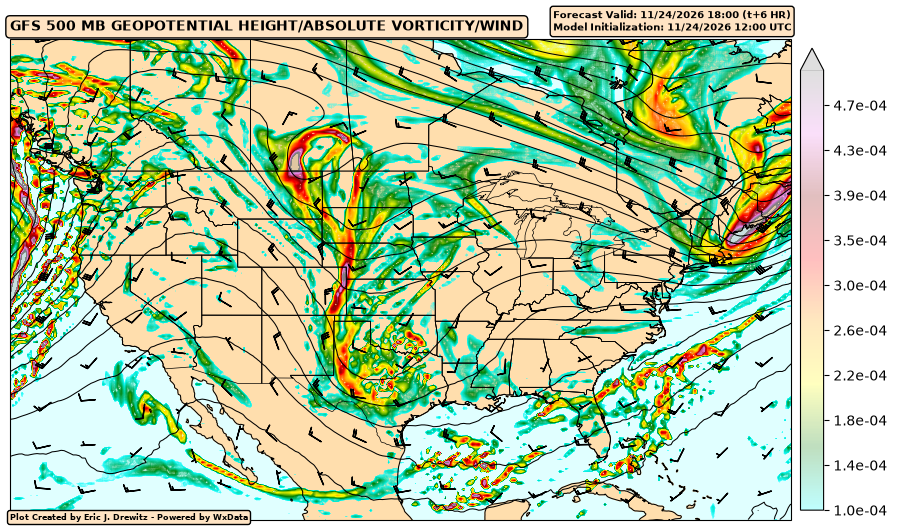

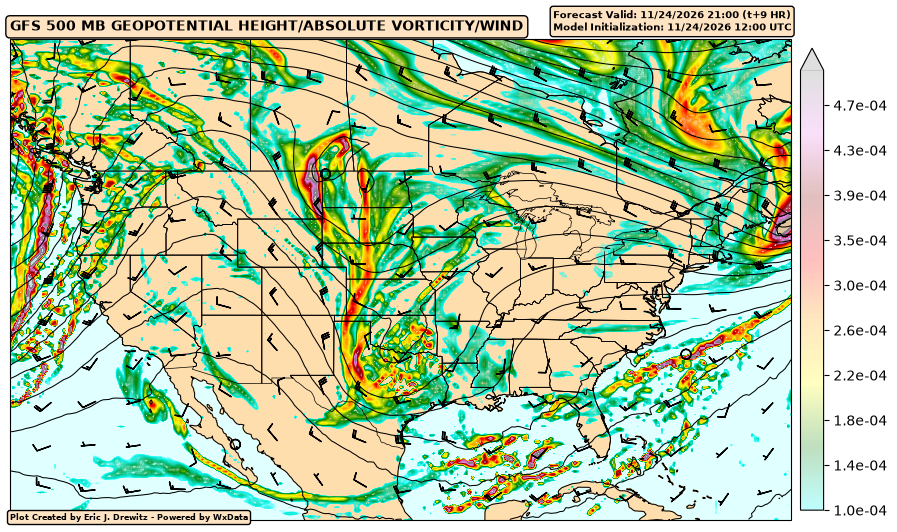

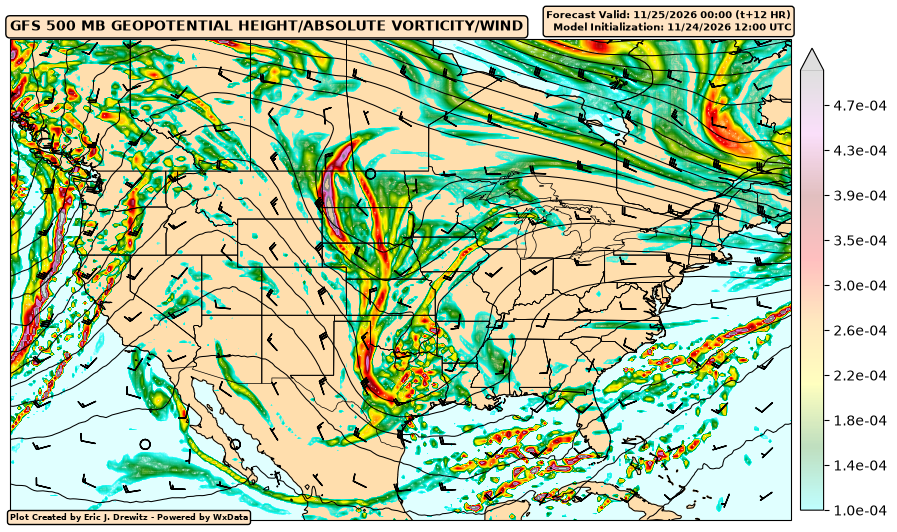

...

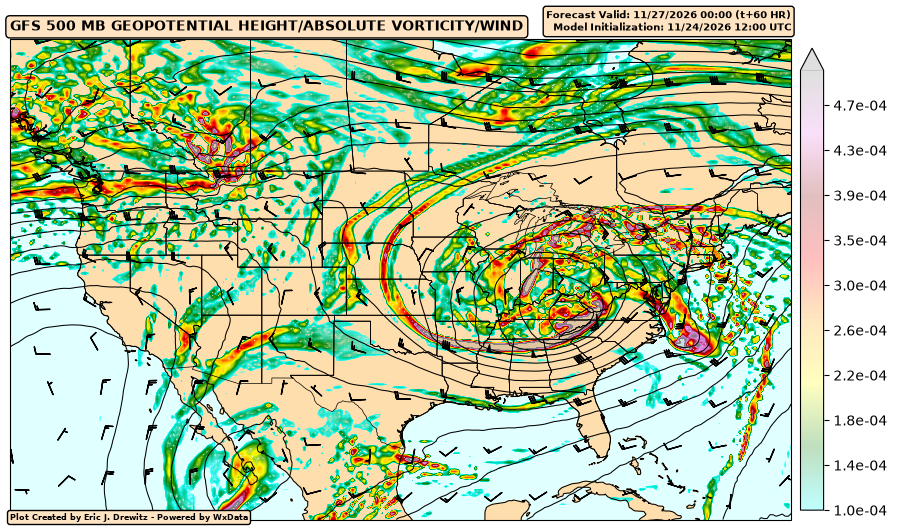

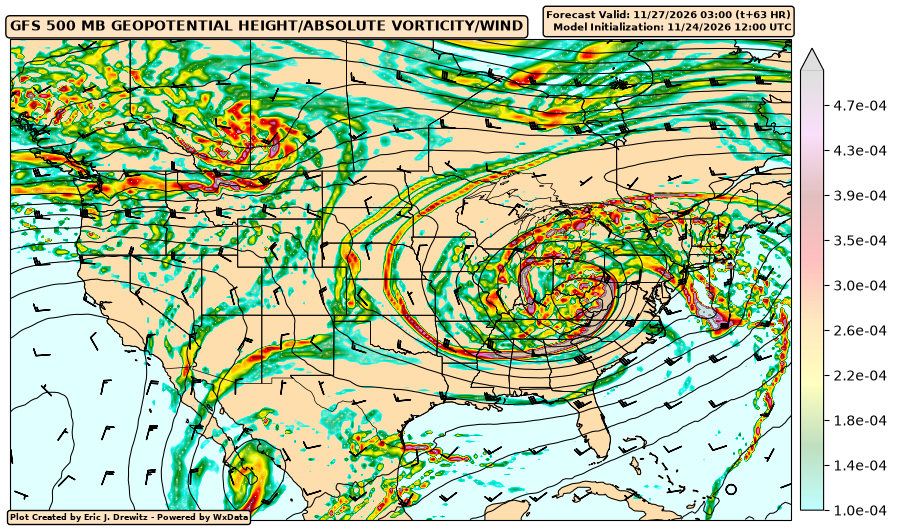

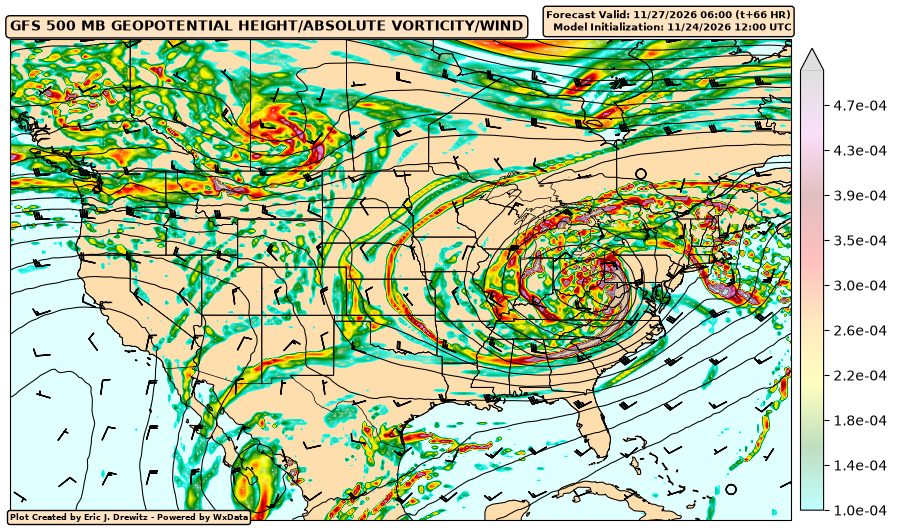

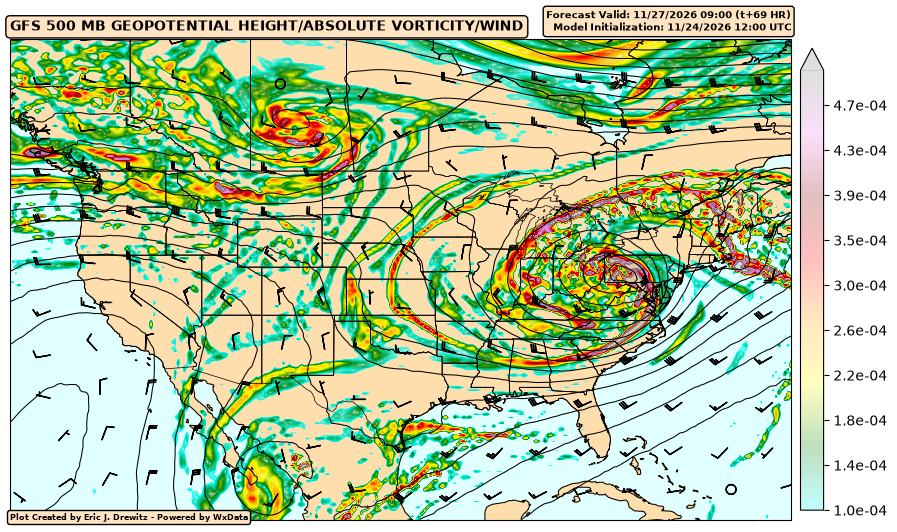

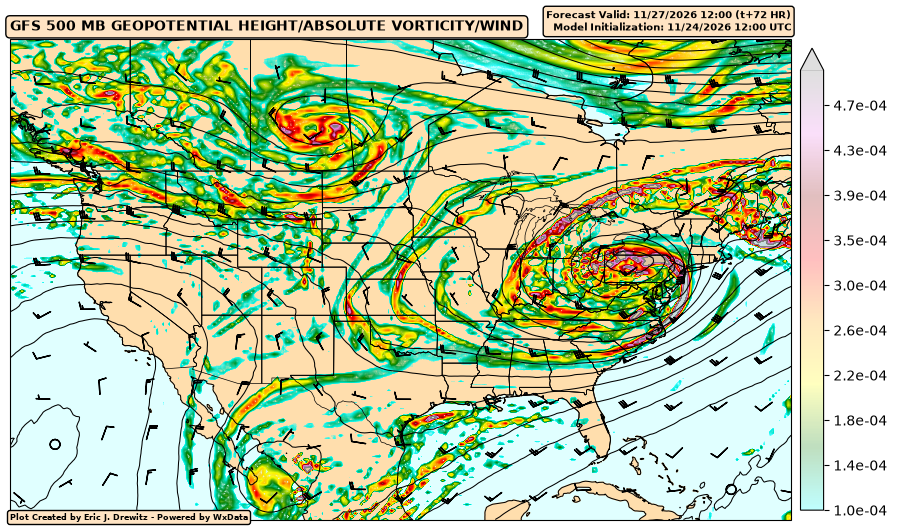

In [4]:
# Plots our data for each frame in the forecast period

for i in range(0, len(ds['step']), 1):

    # Creates our figure
    fig = plt.figure(figsize=(12,12))

    # Creates our figure subplot
    ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())

    # Sets the boundaries of the plot
    ax.set_extent([-130, -65, 20, 60], ccrs.PlateCarree())

    # Adds our coastlines
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.75, zorder=3)

    # Adds the ocean
    ax.add_feature(cfeature.OCEAN, color='lightcyan', zorder=1)

    # Adds lakes
    ax.add_feature(cfeature.LAKES, color='lightcyan', zorder=1)

    # Adds land
    ax.add_feature(cfeature.LAND, color='navajowhite', zorder=1)

    # Adds state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5, zorder=5)

    # Defines Canadian province borders
    province_boundaries = cfeature.NaturalEarthFeature(
    category="cultural",
    name="admin_1_states_provinces_lines",
    scale="50m",
    facecolor="none",
    edgecolor="black",
)

    # Adds Canadian province borders
    ax.add_feature(province_boundaries, linewidth=0.5, zorder=5)

    # Creates our colormap for absolute vorticity
    cmap = LinearSegmentedColormap.from_list("absolute vorticity", 
                                             ['cyan',
                                             'green',
                                             'yellow',
                                             'orange',
                                             'red',
                                             'darkred',
                                             'violet',
                                             'gray'])

    # Plots our geopotential height contours
    c = ax.contour(ds['longitude'], 
                   ds['latitude'], 
                   (ds['geopotential_height'][i, :, :]/ 10), 
                   levels=np.arange(480, 608, 4), 
                   transform=ccrs.PlateCarree(), 
                   colors='black', 
                   linewidths=0.75)

    # Plots our absolute vorticity as filled contours
    cs = ax.contourf(ds['longitude'], 
                   ds['latitude'], 
                   ds['absolute_vorticity'][i, :, :], 
                   levels=np.arange(0.0001, (0.0005 + 0.000001), 0.000001), 
                   transform=ccrs.PlateCarree(),
                   alpha=0.25,
                   cmap=cmap,
                   extend='max')

    # Adds a colorbar for our filled contours
    fig.colorbar(cs, 
                 shrink=0.5, 
                 pad=0.01,
                format='%.1e')

    # Defines the interval for the spacing of the wind barbs
    decimate = 15

    # Creates a 2-D grid for the coordinates of our wind barb
    plot_lon, plot_lat = np.meshgrid(ds['longitude'][::decimate], 
                                      ds['latitude'][::decimate])

    # Defines how our wind barbs will be plotted
    barbs = mpplots.StationPlot(ax, plot_lon.flatten(), plot_lat.flatten(),
                                    transform=ccrs.PlateCarree(), 
                                    clip_on=True)

    # Finds the values of u and v at the points our wind barbs will be plotted
    u = ds['u_wind_component'][i, ::decimate, ::decimate].to_numpy().flatten()
    v = ds['v_wind_component'][i, ::decimate, ::decimate].to_numpy().flatten()

    # Plots our wind barbs
    barbs.plot_barb(u, 
                  v,
                  color='black',
                  length=4.5)

    # Adds our plot title
    plt.title(f"GFS 500 MB GEOPOTENTIAL HEIGHT/ABSOLUTE VORTICITY/WIND", 
                   fontsize=10, 
                   fontweight='bold',
                   bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                   loc='left')
    
    # Extract our valid time as a datetime object
    valid_time = pd.to_datetime(ds['valid_time'].values)
    
    # Gets our new forecast hour (eventhough we are plotting the initial frame)
    times = ds['step'].values
    forecast_time = valid_time + timedelta(hours=int(times[i]))

    # Secondary title for our model runtime
    plt.title(f"Forecast Valid: {forecast_time.strftime('%m/%d/%Y %H:00')} (t+{int(times[i])} HR)\nModel Initialization: {valid_time.strftime('%m/%d/%Y %H:00')} UTC", 
                    fontsize=7, 
                    fontweight='bold',
                    bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                    loc='right')
    
    # Adding my signature on the plot
    ax.text(0, 
            -0.001, 
            f"Plot Created by Eric J. Drewitz - Powered by WxData", 
            transform=ax.transAxes, 
            fontsize=6, 
            fontweight='bold', 
            bbox=dict(boxstyle='round', 
                    facecolor='bisque'))

    # Shows the plot for our frame in the forecast period
    plt.show()